In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR_HMA_evaluation_paper/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import numpy.ma as ma
from scipy import stats
from pyproj import Transformer

In [2]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/stations_central_asia/'
fileCentralAsia='Taver_v1_1.txt'

In [3]:
df_all_stations = pd.read_csv(sourceData+fileCentralAsia, sep="\t") 
df_all_stations

,Country,Code,Name,Long,Lat,Alt,Years,I,II,III,IV,V,VI,VII,VIII,IX,X,XI,XII
0,211,36870.0,Almaty,76.93,43.23,847,1879,-9.8,-6.1,4.5,12.4,18.8,24.3,24.6,21.2,14.5,7.5,-1.5,-4.1
1,211,36870.0,Almaty,76.93,43.23,847,1880,-10.2,-10.9,2.0,7.0,15.8,21.3,22.3,20.1,14.0,10.6,1.5,-6.7
2,211,36870.0,Almaty,76.93,43.23,847,1881,-4.8,6.0,1.1,13.8,16.3,18.6,22.7,21.1,14.9,6.4,-2.0,-11.4
3,211,36870.0,Almaty,76.93,43.23,847,1882,-8.4,-8.9,-2.1,9.7,16.2,20.0,21.5,20.4,15.3,3.2,-1.1,-7.7
4,211,36870.0,Almaty,76.93,43.23,847,1883,-10.7,-14.0,2.8,7.9,16.3,21.3,21.8,21.6,14.3,6.7,-3.4,-6.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12014,231,38712.0,Zaamin,68.40,39.96,626,1988,1.8,2.3,7.3,16.9,19.3,28.1,29.4,26.0,21.4,14.5,12.6,6.4
12015,231,38712.0,Zaamin,68.40,39.96,626,1989,-1.3,-1.4,9.6,13.2,19.2,26.3,29.1,27.3,20.6,16.6,7.6,5.9
12016,231,38712.0,Zaamin,68.40,39.96,626,1990,-0.9,3.5,8.5,13.8,21.5,28.8,28.1,27.2,23.0,14.4,10.0,2.0
12017,231,38712.0,Zaamin,68.40,39.96,626,1991,-0.7,2.6,6.7,15.8,19.4,25.2,28.8,25.8,21.1,15.8,7.6,3.6


In [4]:
station_check = df_all_stations.groupby('Code')['Name'].nunique()
#station_check

In [5]:
duplicates = station_check[station_check > 1]
#print(duplicates)

In [6]:
print(df_all_stations[df_all_stations['Code'] == 35796][['Code','Name', 'Long', 'Lat', 'Alt']].drop_duplicates()
)

        Code     Name   Long   Lat  Alt
224  35796.0  Balhash  75.08  46.8  350


In [7]:
# First, ensure Code_WMO is numeric and drop NaNs for analysis
df_valid_codes = df_all_stations[df_all_stations['Code'].notna()].copy()

# Remove the duplicates (as before)
station_check = df_valid_codes.groupby('Code')['Name'].nunique()
duplicates = station_check[station_check > 1].index.tolist()

# Remove all rows with these duplicated WMO codes
df_clean = df_all_stations[~df_all_stations['Code'].isin(duplicates)].copy()

# Final check
#print("Original rows:", len(df_all_stations))
#print("Rows after removing duplicates:",len(df_clean))


In [8]:
## Model MAR
domain='GRp'
sourceDataGrid='/home/santolam/'
fileName_grF='NST.2014.01.01.00.GRi.nc'
#fileName_grM='NST.2000.01.01.00.GRa_Mera.nc_ICEmask'
dsF= xr.open_dataset(sourceDataGrid+fileName_grF) ## Year mean?
print('lon min',dsF.LON.values.min(),'lon max',dsF.LON.values.max())
print('lat min',dsF.LAT.values.min(),'lat max',dsF.LAT.values.max())

lon_min, lon_max =dsF.LON.values.min(),dsF.LON.values.max()
lat_min, lat_max= dsF.LAT.values.min(),dsF.LAT.values.max()
print(lon_min,lon_max)
print(lat_min,lat_max)

lon min 6.7526566e+01 lon max 77.156975
lat min 36.19467 lat max 41.38051
67.526566 77.156975
36.19467 41.38051


In [9]:
df_dom= df_clean[
    (df_clean['Long'] >= lon_min) & (df_clean['Long'] <= lon_max) &
    (df_clean['Lat'] >= lat_min) & (df_clean['Lat'] <= lat_max)
]

In [10]:
#print(len(df_clean))
#print(len(df_dom))


In [11]:
df_dom[0:5]

,Country,Code,Name,Long,Lat,Alt,Years,I,II,III,IV,V,VI,VII,VIII,IX,X,XI,XII
2491,213,38623.0,Arpa,74.9,40.8,3000,1961,-24.0,-24.0,-15.6,1.2,6.5,8.0,11.3,9.9,6.0,-4.7,-12.3,-20.1
2492,213,38623.0,Arpa,74.9,40.8,3000,1962,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0
2493,213,38623.0,Arpa,74.9,40.8,3000,1963,-26.2,-20.6,-12.5,0.9,6.0,8.5,9.9,9.4,4.2,-0.8,-13.5,-18.8
2494,213,38623.0,Arpa,74.9,40.8,3000,1964,-27.6,-19.8,-10.8,0.0,3.0,6.8,9.4,9.8,4.2,-5.2,-11.2,-20.1
2495,213,38623.0,Arpa,74.9,40.8,3000,1965,-20.1,-21.6,-13.0,0.9,5.2,7.4,10.5,8.7,4.2,-0.7,-17.1,-26.4


In [12]:
# Replace -999.0 (missing value) with NaN
df = df_dom.replace(-999.0, np.nan)

# List of month column names
month_cols = ['I', 'II', 'III', 'IV', 'V', 'VI', 'VII', 'VIII', 'IX', 'X', 'XI', 'XII']

df[month_cols] = df[month_cols].apply(pd.to_numeric, errors='coerce') #if not I have an error, they are strings
df.replace(-999.0, np.nan, inplace=True)


df['DJF'] = (df['XII'].shift(1) + df['I'] + df['II']) / 3 # DJF: Dec (from previous year), Jan, Feb
df['MAM'] = (df['III'] + df['IV'] + df['V']) / 3
df['JJA'] = (df['VI'] + df['VII'] + df['VIII']) / 3
df['SON'] = (df['IX'] + df['X'] + df['XI']) / 3
df['Annual'] = df[month_cols].mean(axis=1, skipna=True)

# Now include it in your seasonal_means DataFrame
seasonal_means = df[['Code', 'Name', 'Long', 'Lat', 'Alt', 'Years', 
                     'DJF', 'MAM', 'JJA', 'SON', 'Annual']]
#stations_list=[]
grouped = seasonal_means.groupby('Code')

stations_dict = {}
for wmo_code, group in grouped:
    group = group.reset_index(drop=True)
    #stations_list.append(group)  # for iteration
    stations_dict[wmo_code] = group.set_index('Years')  # for direct lookup and time series


In [13]:
#print(len(seasonal_means))

In [14]:
#print(seasonal_means[0:5])

In [15]:
ann_clim = (
    seasonal_means
    .groupby(['Code', 'Name', 'Long', 'Lat', 'Alt'], as_index=False)
    .agg(
        iyear=('Years', 'min'),
        fyear=('Years', 'max'),
        ann_mean=('Annual', 'mean')
    )
)

In [16]:
ann_clim

,Code,Name,Long,Lat,Alt,iyear,fyear,ann_mean
0,36969.0,Atbashi,75.80,41.20,2025,1961,1995,1.974762
1,36994.0,Chatirkul,75.80,40.60,3540,1961,1988,-5.370346
2,38447.0,Kaunchi,69.00,41.08,340,1927,1999,13.244841
3,38457.0,Tashkent,69.30,41.33,477,1875,2003,13.695164
4,38460.0,Dukant,70.07,41.15,2001,1959,2001,7.830943
...,...,...,...,...,...,...,...,...
71,38947.0,Nizhniy Pyandge,68.58,37.20,329,1947,1990,17.206671
72,38951.0,Rushan,71.52,37.95,1981,1951,1990,9.762061
73,38954.0,Horog,71.50,37.50,2075,1899,2003,8.513830
74,38957.0,Ishkashim,71.60,36.73,2523,1951,1990,6.875578


In [17]:
#station_info['Long'].values

In [18]:

lat_stas =ann_clim['Lat'].values   #extract_column_float(data_dicts, 'Lat')
lon_stas = ann_clim['Long'].values 
elev_stas= ann_clim['Alt'].values 
codes =ann_clim['Code'].values

lon_MAR=dsF.LON;lat_MAR=dsF.LAT
iMAR_sta=[];jMAR_sta=[] ##coord of MAR pixel corresponding to station location

for pos in np.arange(len(lat_stas)):
    target_lon,target_lat=float(lon_stas[pos]),float(lat_stas[pos])
    # Compute distance to each grid point
    dist = np.sqrt((lon_MAR - target_lon)**2 + (lat_MAR - target_lat)**2)
    j, i = np.unravel_index(dist.argmin(), dist.shape) 
    jMAR_sta.append(j);iMAR_sta.append(i)

In [19]:
##Comparison of elevation (for example) at one point
SH_MAR_sta=dsF.SH[jMAR_sta[0],iMAR_sta[0]]
dif=elev_stas[0]-SH_MAR_sta.values
#print(dif)

In [20]:
##For all points
SHList_dom=[];LONList_dom=[];LATList_dom=[]
for k in range(len(jMAR_sta)):
    tmp=dsF.SH[jMAR_sta[k],iMAR_sta[k]]
    SHList_dom.append(tmp)
    tmp1=dsF.LON[jMAR_sta[k],iMAR_sta[k]]
    LONList_dom.append(tmp1)
    tmp2=dsF.LAT[jMAR_sta[k],iMAR_sta[k]]
    LATList_dom.append(tmp2)


In [21]:
ds_stations_MARgrid= [{
    'codes_wmo':int(codes[i]),
    'lat_sta_ori': lat_stas[i],
    'lon_sta_ori':lon_stas[i],
    'elev_station_ori': elev_stas[i],
    'pix_i_sta_mar':iMAR_sta[i], ## coord i,j: Position of station in the pixel of MAR grid (the closest)
    'pix_j_sta_mar':jMAR_sta[i], ## coord i,j: Position of station in the pixel of MAR grid (the closest)
    'elev_MAR_pix': SHList_dom[i].values,
    'lat_mar':LATList_dom[i].values, #Same as pix i,j to test that it it the same point
    'lon_mar':LONList_dom[i].values
} for i in range(len(SHList_dom))]


df_stations_MARgrid= pd.DataFrame(ds_stations_MARgrid)


In [22]:
#print(len(df_stations_MARgrid['elev_MAR_pix']))

In [23]:
df_stations_MARgrid[0:5]

,codes_wmo,lat_sta_ori,lon_sta_ori,elev_station_ori,pix_i_sta_mar,pix_j_sta_mar,elev_MAR_pix,lat_mar,lon_mar
0,36969,41.20,75.80,2025,99,79,2652.819,41.20258,75.81277
1,36994,40.60,75.80,3540,99,69,3680.7898,40.574116,75.78022
2,38447,41.08,69.00,340,17,77,330.42392,41.081726,68.96056
3,38457,41.33,69.30,477,21,81,514.09454,41.34211,69.28284
4,38460,41.15,70.07,2001,30,78,1701.1609,41.17025,70.04299


In [24]:
#len(df_stations_MARgrid['elev_MAR_pix'])

In [25]:
##PRECIP comparison

In [31]:
domainM='GRp';
ds_TTZ_raw=xr.open_mfdataset('/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/GRp/spin2/work/monthly/'+
    'TTZ_monmean_MARv3.14_ER5_spin2_GRp_*.nc')['TTZ'].sel(ZTQLEV=2)
ds_TTZ= ds_TTZ_raw.rename({'TIME': 'time'})
ds_TTZ=ds_TTZ#[:,ny:-ny,nx:-nx]

iyr,fyr=1950,1990
#ds_TTZ=ds_TTZ.sel(time=slice("1950",fyr))
ds_TTZ = ds_TTZ.sel(time=slice("1950-01-01", f"{fyr}-12-31"))

dsSH=dsF.SH

In [32]:
from scipy import stats

def monthly_lapse_rate(ds_TTZ, dsSH):
    """
    Compute lapse rate (°C/km) for monthly temperature data.

    Parameters
    ----------
    ds_TTZ : xarray.DataArray
        Temperature data (monthly) [time, lat, lon]
    dsSH : xarray.DataArray
        Surface height (elevation) [lat, lon]

    Returns
    -------
    xarray.DataArray
        Monthly lapse rate in °C/km
    """
    lapse_rates = []
    for t in ds_TTZ.time:
        T = ds_TTZ.sel(time=t).values.flatten()
        Z = dsSH.values.flatten()
        mask = np.isfinite(T) & np.isfinite(Z)

        slope, _, _, _, _ = stats.linregress(Z[mask], T[mask])
        lapse_rates.append(slope * 1000)  # °C/km

    return xr.DataArray(
        lapse_rates,
        coords=[ds_TTZ.time],
        dims=["time"],
        name="lapse_rate"
    )

# Example usage:
lr_monthly = monthly_lapse_rate(ds_TTZ, dsSH)
print(lr_monthly.shape)


(492,)


In [33]:
#months = ["I","II","III","IV","V","VI","VII","VIII","IX","X","XI","XII"] 
#Z = bias_mat.values #(station × month) # 
#ylabels = ["WMO (alt m)", ...] # n_years = array/list of number of years for each station, same order as ylabels # Define discrete intervals for the bias (mm) bounds = np.arange(-10, 11, 1) # adjust according to your data cmap = plt.get_cmap("RdBu_r", len(bounds)-1) # discrete BrBG norm = mcolors.BoundaryNorm(bounds, cmap.N) # Grid for pcolormesh x = np.arange(len(months) + 1) y = np.arange(len(ylabels) + 1) fig, ax = plt.subplots(figsize=(10, 18)) # Plot bias pcm = ax.pcolormesh( x, y, Z, cmap=cmap, norm=norm, shading="auto" ) # Horizontal lines for each station for yy in range(len(ylabels)): ax.axhline(yy, color="k", lw=0.3, alpha=0.3) # Left y-axis: WMO + elevation ax.set_yticks(np.arange(len(ylabels)) + 0.5) ax.set_yticklabels(ylabels) ax.set_ylabel("Station (WMO code, elevation)") # Right y-axis: number of years ax2 = ax.twinx() ax2.set_ylim(ax.get_ylim()) # align with left y-axis ax2.set_yticks(np.arange(len(ylabels)) + 0.5) ax2.set_yticklabels(n_years) # n_years in same order as ylabels ax2.set_ylabel("Number of years (from 1980)") # X-axis ax.set_xticks(np.arange(len(months)) + 0.5) ax.set_xticklabels(months) ax.set_xlabel("Month") cbar_ax = fig.add_axes([1., 0.15, 0.05, 0.7]) # [left, bottom, width, height] in figure coords cbar = fig.colorbar(pcm, cax=cbar_ax, orientation='vertical', ticks=bounds) cbar.set_label("°C") # Title ax.set_title( "Monthly temperaute bias $\Delta$(MAR − OBS)\n" #"Stations ordered by elevation (low → high)" ) #plt.tight_layout() plt.show()

In [34]:
#lr_monthly

In [35]:
#vals,anoms=climb.seasonal_selection(ds_TF,'DJF',1980,2024)

vals,anoms=climb.seasonal_selection(ds_TTZ,'JFMAMJJASOND',iyr,fyr)
#vals.time


In [36]:
lr_annual = lr_monthly.groupby('time.year').mean('time')

In [37]:
df_stations_MARgrid[0:5]

,codes_wmo,lat_sta_ori,lon_sta_ori,elev_station_ori,pix_i_sta_mar,pix_j_sta_mar,elev_MAR_pix,lat_mar,lon_mar
0,36969,41.20,75.80,2025,99,79,2652.819,41.20258,75.81277
1,36994,40.60,75.80,3540,99,69,3680.7898,40.574116,75.78022
2,38447,41.08,69.00,340,17,77,330.42392,41.081726,68.96056
3,38457,41.33,69.30,477,21,81,514.09454,41.34211,69.28284
4,38460,41.15,70.07,2001,30,78,1701.1609,41.17025,70.04299


In [38]:
#print(dsF.SH.shape)

In [39]:
ts_mar = vals.isel(Y=j, X=i)

In [40]:

mar_rows = []

for _, row in df_stations_MARgrid.iterrows():
    code = int(row.codes_wmo)
    i = int(row.pix_i_sta_mar)
    j = int(row.pix_j_sta_mar)
    
    # Extract MAR monthly time series for this station
    ts_mar = ds_TTZ.isel(Y=j, X=i)  # adjust dimension names if needed

    # Elevation difference in km
    dz = (row.elev_station_ori - row.elev_MAR_pix) / 1000

    # Apply lapse-rate correction: T_corr = T_MAR + Gamma * dz
    ts_mar_corr = ts_mar + lr_monthly * dz
    
    # Save as DataFrame
    mar_df = pd.DataFrame({
        'Code_WMO': code,
        'Time': ts_mar.time.values,
        'MAR_Original': ts_mar.values,
        'MAR_Corrected': ts_mar_corr.values
    })

    mar_rows.append(mar_df)

df_mar_monthly = pd.concat(mar_rows, ignore_index=True)


In [41]:
df_mar_monthly

,Code_WMO,Time,MAR_Original,MAR_Corrected
0,36969,1950-01-16 12:00:00,-9.954453,-7.165794
1,36969,1950-02-15 00:00:00,-11.098701,-7.823781
2,36969,1950-03-16 12:00:00,-2.467607,1.283149
3,36969,1950-04-16 00:00:00,1.209171,5.146521
4,36969,1950-05-16 12:00:00,9.504204,13.820086
...,...,...,...,...
37387,38966,1990-08-16 12:00:00,7.963985,11.280484
37388,38966,1990-09-16 00:00:00,3.624320,6.678443
37389,38966,1990-10-16 12:00:00,-5.231232,-2.244712
37390,38966,1990-11-16 00:00:00,-10.029354,-7.144247


In [42]:
df_stations_MARgrid

,codes_wmo,lat_sta_ori,lon_sta_ori,elev_station_ori,pix_i_sta_mar,pix_j_sta_mar,elev_MAR_pix,lat_mar,lon_mar
0,36969,41.20,75.80,2025,99,79,2652.819,41.20258,75.81277
1,36994,40.60,75.80,3540,99,69,3680.7898,40.574116,75.78022
2,38447,41.08,69.00,340,17,77,330.42392,41.081726,68.96056
3,38457,41.33,69.30,477,21,81,514.09454,41.34211,69.28284
4,38460,41.15,70.07,2001,30,78,1701.1609,41.17025,70.04299
...,...,...,...,...,...,...,...,...,...
71,38947,37.20,68.58,329,10,16,378.977,37.230194,68.584595
72,38951,37.95,71.52,1981,47,27,2630.3953,37.978943,71.50143
73,38954,37.50,71.50,2075,47,19,2794.1304,37.475414,71.506905
74,38957,36.73,71.60,2523,48,7,3935.6606,36.720734,71.59342


In [43]:
###to avoid problem with dask
ds_TTZ = ds_TTZ.compute()
lr_annual = lr_annual.compute()

In [44]:
rows = []

for _, row in df_stations_MARgrid.iterrows():
    code = int(row.codes_wmo)
    sta = stations_dict[code]
    sta_years = sta.index.astype(int)
    sta_ann = sta['Annual']
    
    ts_mar = ds_TTZ.isel(Y=row.pix_j_sta_mar, X=row.pix_i_sta_mar)

    dz = (row.elev_station_ori - row.elev_MAR_pix) / 1000

    # --- compute overlapping period
    iyear = max(sta_years.min(), lr_annual.year.min().item())
    fyear = min(sta_years.max(), lr_annual.year.max().item())

    if iyear > fyear:
        continue

    # --- overlapping station annual series
    sta_c = sta_ann.loc[iyear:fyear]

    # --- select MAR annual mean for overlapping period
    mar_c = ts_mar.sel(time=slice(f'{iyear}-01-01', f'{fyear}-12-31'))
    mar_c_ann = mar_c.groupby('time.year').mean('time')
    
    # --- select lapse rate for overlapping years
    lr_c = lr_annual.sel(year=slice(iyear, fyear))

    # --- apply lapse-rate correction year by year
    ts_mar_corr_ann = mar_c_ann + lr_c * dz

    # --- climatological means
    rows.append({
        'Code_WMO': code,
        'iyear': iyear,
        'fyear': fyear,
        'ann_mean_obs': sta_c.mean(),
        'ann_mean_MAR': mar_c_ann.mean().item(),
        'ann_mean_MAR_corr': ts_mar_corr_ann.mean().item(),
        'bias_MAR-sta': mar_c_ann.mean().item() - sta_c.mean(),
        'bias_MAR-sta_corr': ts_mar_corr_ann.mean().item() - sta_c.mean(),
        'elev_sta': row.elev_station_ori,
        'elev_MAR_pix': row.elev_MAR_pix
    })

df_clim_MAR = pd.DataFrame(rows)


In [45]:
df_clim_MAR

,Code_WMO,iyear,fyear,ann_mean_obs,ann_mean_MAR,ann_mean_MAR_corr,bias_MAR-sta,bias_MAR-sta_corr,elev_sta,elev_MAR_pix
0,36969,1961,1990,2.050833,1.572505,5.243737,-0.478328,3.192903,2025,2652.819
1,36994,1961,1988,-5.370346,-3.687677,-2.864730,1.682669,2.505616,3540,3680.7898
2,38447,1950,1990,13.125631,12.795510,12.739586,-0.330121,-0.386046,340,330.42392
3,38457,1950,1990,13.926626,13.123665,13.340296,-0.802961,-0.586330,477,514.09454
4,38460,1959,1990,7.681250,6.664212,4.913171,-1.017038,-2.768079,2001,1701.1609
...,...,...,...,...,...,...,...,...,...,...
71,38947,1950,1990,17.218523,15.183155,15.475017,-2.035368,-1.743506,329,378.977
72,38951,1951,1990,9.762061,8.315737,12.111873,-1.446324,2.349813,1981,2630.3953
73,38954,1950,1990,8.940152,7.070315,11.270007,-1.869836,2.329855,2075,2794.1304
74,38957,1951,1990,6.875578,-4.538095,3.719821,-11.413674,-3.155757,2523,3935.6606


In [46]:
df = df_clim_MAR.merge(
    df_stations_MARgrid,
    left_on='Code_WMO',
    right_on='codes_wmo',
    how='inner'
)

df

,Code_WMO,iyear,fyear,ann_mean_obs,ann_mean_MAR,ann_mean_MAR_corr,bias_MAR-sta,bias_MAR-sta_corr,elev_sta,elev_MAR_pix_x,codes_wmo,lat_sta_ori,lon_sta_ori,elev_station_ori,pix_i_sta_mar,pix_j_sta_mar,elev_MAR_pix_y,lat_mar,lon_mar
0,36969,1961,1990,2.050833,1.572505,5.243737,-0.478328,3.192903,2025,2652.819,36969,41.20,75.80,2025,99,79,2652.819,41.20258,75.81277
1,36994,1961,1988,-5.370346,-3.687677,-2.864730,1.682669,2.505616,3540,3680.7898,36994,40.60,75.80,3540,99,69,3680.7898,40.574116,75.78022
2,38447,1950,1990,13.125631,12.795510,12.739586,-0.330121,-0.386046,340,330.42392,38447,41.08,69.00,340,17,77,330.42392,41.081726,68.96056
3,38457,1950,1990,13.926626,13.123665,13.340296,-0.802961,-0.586330,477,514.09454,38457,41.33,69.30,477,21,81,514.09454,41.34211,69.28284
4,38460,1959,1990,7.681250,6.664212,4.913171,-1.017038,-2.768079,2001,1701.1609,38460,41.15,70.07,2001,30,78,1701.1609,41.17025,70.04299
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,38947,1950,1990,17.218523,15.183155,15.475017,-2.035368,-1.743506,329,378.977,38947,37.20,68.58,329,10,16,378.977,37.230194,68.584595
72,38951,1951,1990,9.762061,8.315737,12.111873,-1.446324,2.349813,1981,2630.3953,38951,37.95,71.52,1981,47,27,2630.3953,37.978943,71.50143
73,38954,1950,1990,8.940152,7.070315,11.270007,-1.869836,2.329855,2075,2794.1304,38954,37.50,71.50,2075,47,19,2794.1304,37.475414,71.506905
74,38957,1951,1990,6.875578,-4.538095,3.719821,-11.413674,-3.155757,2523,3935.6606,38957,36.73,71.60,2523,48,7,3935.6606,36.720734,71.59342


In [47]:
# Derived variables
df['delta_z'] = df['elev_MAR_pix_x'] - df['elev_sta']
df['bias'] = df['bias_MAR-sta']
df['bias_corr'] = df['bias_MAR-sta_corr']


In [48]:
plotsDir='/home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/'

In [49]:
fz=18

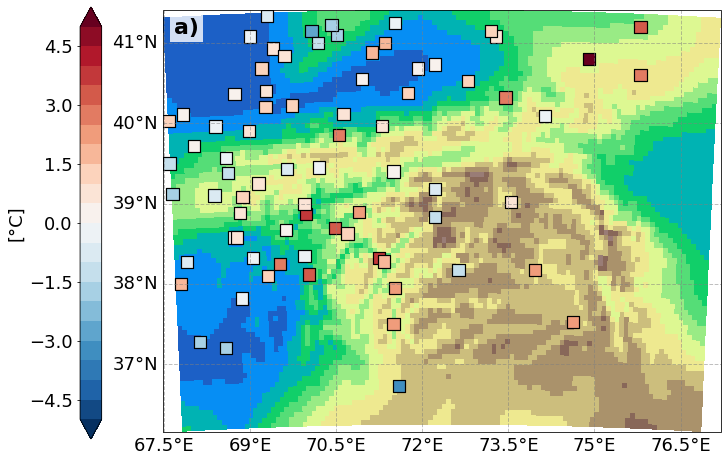

In [50]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs

# =========================
# COLORMAP (BIAS)
# =========================
clevs = np.arange(-5, 5.5, 0.5)
cmap_bias = plt.get_cmap('RdBu_r')
norm_bias = mcolors.BoundaryNorm(clevs, cmap_bias.N, extend='both')

# =========================
# FIGURE
# =========================
fig = plt.figure(figsize=(10, 12))
ax = plt.axes(projection=ccrs.PlateCarree())

# =========================
# BACKGROUND: MAR elevation
# =========================
#m1 = ax.pcolormesh(
#    dsF.LON, dsF.LAT, dsF.SH,
#    cmap='Greys',
#    shading='auto',
##    transform=ccrs.PlateCarree()
#)

clevs_mod = np.arange(0, 7500, 500)
cmap_mod = plt.get_cmap('terrain')
norm = mcolors.BoundaryNorm(boundaries=clevs_mod, ncolors=cmap_mod.N, extend="both")

m1 = ax.pcolormesh(dsF.LON, dsF.LAT, dsF.SH, 
                       transform=ccrs.PlateCarree(),
                       cmap=cmap_mod, norm=norm, shading='auto')


# =========================
# STATIONS: BIAS
# =========================
sc = ax.scatter(
    df['lon_sta_ori'], df['lat_sta_ori'],
    c=df['bias_corr'],                      # <-- aquí tu variable clave
    cmap=cmap_bias,
    norm=norm_bias,
    s=150, marker='s',
    edgecolors='black',
    linewidths=1.2,
    transform=ccrs.PlateCarree()
)

# =========================
gl = ax.gridlines(draw_labels=True, linewidth=1, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False
#gl.right_labels = Tr#
gl.xlabel_style = {"size": fz}
gl.ylabel_style = {"size": fz}

# =========================
# COLORBAR
# =========================
#cbar_ax = fig.add_axes([0.25, 0.16, 0.5, 0.03])  # [left, bottom, width, height]
cbar_ax = fig.add_axes([0.01, 0.25, 0.03, 0.5])    # [left, bottom, width, height]
cbar = plt.colorbar(sc, cax=cbar_ax, orientation='vertical', pad=0.08, shrink=0.8)

cbar.ax.yaxis.set_label_position('left')
cbar.ax.yaxis.set_ticks_position('left')

cbar.set_label('[°C]', fontsize=fz)
cbar.ax.tick_params(labelsize=fz)

# --- Shared colorbar ---
#cbar_ax1 = fig.add_axes([0.25, 0.1, 0.6, 0.03])  # [left, bottom, width, height]
#cbar1 = fig.colorbar(m1, cax=cbar_ax1, orientation="horizontal")
#cbar1.set_label("Elevation [m a.s.l.]", fontsize=18)
#cbar1.ax.tick_params(labelsize=18)
# =========================
# PANEL LABEL
# =========================
ax.text(
    0.02, 0.98, 'a)',
    transform=ax.transAxes,
    fontsize=22,
    fontweight='bold',
    va='top',
    bbox=dict(facecolor='white', alpha=0.8, edgecolor='none')
)

# =========================
# OPTIONAL (MUY RECOMENDADO)
# =========================
#ax.set_title('MAR Temperature Bias (°C)', fontsize=16)
ax.set_aspect(1.4)
# =========================
# SAVE / SHOW
# =========================
#plt.tight_layout()
#print(plotsDir)
#plotname='FIG9a_bias_corr_TTZ_stations_centralasia_rev1_Fanny1990'
#plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
#print(f"Saved: {plotsDir}{plotname}.png")
plt.show()

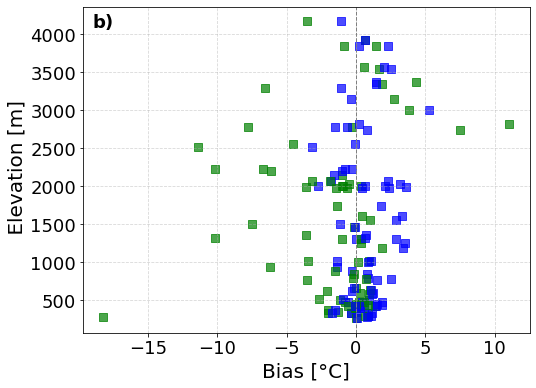

In [56]:
fz=20
# Compute the overlapping period
df_clim_MAR['period'] = df_clim_MAR['fyear'] - df_clim_MAR['iyear'] + 1

# Define a function to choose marker based on period
#def get_marker(period):
#    if period  < 5:
#        return 's'  # square
#    elif 5 <= period < 10:
#        return 'o'  # circle
#    elif 10 <= period < 20:
#        return 'X'  # circle
#    else:
#        return 'D'  # diamond for >10 years

plt.figure(figsize=(8,6))

# Loop through each row and plot with appropriate marker
for _, row in df_clim_MAR.iterrows():
    plt.scatter(row['bias_MAR-sta'], row['elev_sta'], marker='s',
                color='green', alpha=0.7, s=80)
    plt.scatter(row['bias_MAR-sta_corr'], row['elev_sta'], marker='s',
                color='blue', alpha=0.7, s=80)

plt.axvline(0, color='grey', linestyle='--', linewidth=1)
#plt.xlabel('Bias MAR - Station (Annual Mean)')
plt.xlabel('Bias [°C]',fontsize=fz)
plt.ylabel(' Elevation [m]',fontsize=fz)
#plt.title('Bias vs Station Elevation (Marker: overlapping period)')
plt.grid(True, linestyle='--', alpha=0.5)

# Optional legend
#from matplotlib.lines import Line2D
#legend_elements = [
    #Line2D([0], [0], marker='^', color='w', label='<1 year', markerfacecolor='blue', markersize=8),
#    Line2D([0], [0], marker='s', color='w', label='1-5 years', markeredgecolor='black',markerfacecolor='none', markersize=8),
#    Line2D([0], [0], marker='o', color='w', label='5-10 years',markeredgecolor='black', markerfacecolor='none', markersize=8),
##    Line2D([0], [0], marker='D', color='w', label='10-20 years',markeredgecolor='black', markerfacecolor='none', markersize=8),
#    Line2D([0], [0], marker='X', color='w', label='>20 years', markeredgecolor='black',markerfacecolor='none', markersize=8)
#]
#plt.legend(handles=legend_elements, title='Overlap period')
ax = plt.gca()

ax.text(
    0.02, 0.98,            # position relative à l'axe
    'b)',
    transform=ax.transAxes,
    fontsize=18,
    fontweight='bold',
    va='top',
    ha='left',
    bbox=dict(facecolor='white', edgecolor='none', alpha=0.9, pad=2)
)

plt.rcParams.update({
    "font.size": 18,
    "axes.labelsize": 18,
    "axes.titlesize": 18,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 18,
    "figure.titlesize": 18,
})

#plotname = f"FIG9b_scatter_central_asia_Tavg.{domain}_SH_ICE_pamir_rev1_Fanny1990"
#plt.tight_layout()
#plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
#print(f"Saved: {plotsDir}{plotname}.png")

plt.show()
